In [34]:
#Pranjal Gupta
#2026B15310107
#Section - AIML4

# Retail Demand Forecasting & Backtesting

**Project 03 | Daily sales across a small simulated retail network**

## What this notebook does

The aim is to take daily sales data, check whether it is usable as a time series, prepare a few features, and see how two simple forecasting approaches perform. I have kept the models simple on purpose: first, it is useful to have a baseline before trying more complicated models.

The data is **synthetic** (generated for this project), not collected from an actual retailer. It has been set up to include patterns that often matter in retail, such as weekday changes, seasonal effects, promotions, price changes, holidays and occasional stock limits.

## Dataset at a glance

- 5 stores and 20 products
- Daily data from 1 January 2024 to 31 December 2025 (731 dates, including the 2024 leap day)
- One sales row per date, store and product (73,100 rows)
- Separate files for sales, products, stores and calendar information

The supplied CSV files are already generated, so the notebook can be run without recreating the data. A fixed random seed was used when the data was made.


## 1. Load the data

Pandas handles the tables, NumPy is used for the metric calculations, and Matplotlib is used for a few plots. Keep the notebook in the same folder as `data/` so these relative file paths work.


In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded1 = files.upload()
filename1 = next(iter(uploaded1))
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_DIR = Path("data")
sales = pd.read_csv(filename1,sep=',')

uploaded2 = files.upload()
filename2 = next(iter(uploaded2))
products = pd.read_csv(filename2,sep=',')

uploaded3 = files.upload()
filename3 = next(iter(uploaded3))
stores = pd.read_csv(filename3,sep=',')

uploaded4 = files.upload()
filename4 = next(iter(uploaded4))
calendar = pd.read_csv(filename4,sep=',')

pd.set_option("display.max_columns", 30)
print("Sales shape:", sales.shape)
sales.head()


Saving sales_daily.csv to sales_daily (5).csv


Saving products.csv to products (3).csv


Saving stores.csv to stores (3).csv


Saving calendar.csv to calendar (3).csv
Sales shape: (73100, 8)


,Date,Store_ID,Product_ID,Units_Sold,Inventory_Available,Stockout_Flag,Selling_Price,Promotion
0,2024-01-01,ST01,P001,19,32,0,20.49,0
1,2024-01-02,ST01,P001,24,42,0,20.22,0
2,2024-01-03,ST01,P001,33,39,0,20.19,0
3,2024-01-04,ST01,P001,32,50,0,19.90,0
4,2024-01-05,ST01,P001,34,55,0,19.92,0


In [20]:
sales.info()
products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 73100 non-null  object 
 1   Store_ID             73100 non-null  object 
 2   Product_ID           73100 non-null  object 
 3   Units_Sold           73100 non-null  int64  
 4   Inventory_Available  73100 non-null  int64  
 5   Stockout_Flag        73100 non-null  int64  
 6   Selling_Price        73100 non-null  float64
 7   Promotion            73100 non-null  int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 4.5+ MB


,"Product_ID,Product_Name,Category,Base_Price"
0,"P001,Bottled Water,Beverages,20"
1,"P002,Orange Juice,Beverages,65"
2,"P003,Cola,Beverages,40"
3,"P004,Milk,Dairy,32"
4,"P005,Yogurt,Dairy,25"


## 2. First checks: is the data in good shape?

Each row is meant to represent one **Date + Store_ID + Product_ID** combination. Before doing any analysis, check for missing values, repeated keys and gaps in the dates. If these checks fail on a real dataset, it is worth finding out why before filling or deleting anything.


In [18]:
KEYS = ["Date", "Store_ID", "Product_ID"]

print("Data types:")
display(sales.dtypes.to_frame("dtype"))

print("\\nMissing values:")
display(sales.isna().sum().to_frame("missing_count"))

duplicate_count = sales.duplicated(KEYS).sum()
print("Duplicate date-store-product keys:", duplicate_count)

print("Date range:", sales["Date"].min(), "to", sales["Date"].max())
expected_dates = pd.date_range(sales["Date"].min(), sales["Date"].max(), freq="D")
observed_dates = pd.DatetimeIndex(sales["Date"].drop_duplicates().sort_values())
missing_dates = expected_dates.difference(observed_dates)
print("Missing calendar dates:", len(missing_dates))

series_coverage = sales.groupby(["Store_ID", "Product_ID"])["Date"].nunique()
print("Expected dates per series:", len(expected_dates))
print("Series with incomplete date coverage:", int((series_coverage != len(expected_dates)).sum()))

Data types:


,dtype
Date,object
Store_ID,object
Product_ID,object
Units_Sold,int64
Inventory_Available,int64
Stockout_Flag,int64
Selling_Price,float64
Promotion,int64


\nMissing values:


,missing_count
Date,0
Store_ID,0
Product_ID,0
Units_Sold,0
Inventory_Available,0
Stockout_Flag,0
Selling_Price,0
Promotion,0


Duplicate date-store-product keys: 0
Date range: 2024-01-01 to 2025-12-31
Missing calendar dates: 0
Expected dates per series: 731
Series with incomplete date coverage: 0


### Reading these checks

If the duplicate count is zero, each date-store-product combination appears only once. Complete date coverage means every series has an observation for every date in the period. In a real business dataset, a missing date does not automatically mean zero sales: it could also mean the store was closed or the data was not recorded.


## 3. Add product, store and calendar details

The sales file contains the main observations. The other files add useful labels and date information. These are left joins, and the validation checks help catch accidental many-to-many joins that could duplicate sales rows.


In [22]:
row_count_before = len(sales)

data = (
    sales
    .merge(products, on="Product_ID", how="left", validate="many_to_one")
    .merge(stores, on="Store_ID", how="left", validate="many_to_one")
    .merge(calendar, on="Date", how="left", validate="many_to_one")
)

assert len(data) == row_count_before, "A join unexpectedly changed the row count."
print("Joined dataset shape:", data.shape)
display(data.head())

Joined dataset shape: (73100, 22)


,Date,Store_ID,Product_ID,Units_Sold,Inventory_Available,Stockout_Flag,Selling_Price,Promotion,Product_Name,Category,Base_Price,City,Store_Type,Day_Name,Day_Of_Week,Month,Quarter,Is_Weekend,Is_Month_Start,Is_Month_End,Is_Holiday,Seasonal_Promo_Period
0,2024-01-01,ST01,P001,19,32,0,20.49,0,Bottled Water,Beverages,20,Delhi,Urban,Monday,0,1,1,0,1,0,0,0
1,2024-01-02,ST01,P001,24,42,0,20.22,0,Bottled Water,Beverages,20,Delhi,Urban,Tuesday,1,1,1,0,0,0,0,0
2,2024-01-03,ST01,P001,33,39,0,20.19,0,Bottled Water,Beverages,20,Delhi,Urban,Wednesday,2,1,1,0,0,0,0,0
3,2024-01-04,ST01,P001,32,50,0,19.90,0,Bottled Water,Beverages,20,Delhi,Urban,Thursday,3,1,1,0,0,0,0,0
4,2024-01-05,ST01,P001,34,55,0,19.92,0,Bottled Water,Beverages,20,Delhi,Urban,Friday,4,1,1,0,0,0,0,0


## 4. A quick look at sales

The main forecasting unit stays at product-store-day level. The summary below rolls sales up to store-day level just to make the overall pattern easier to see.

One thing to keep in mind: **units sold are not always the same as customer demand**. If a product sells out, some customers may not be able to buy it. The stockout flag helps us spot those cases, but it cannot tell us exactly how many units we missed.


,Date,Store_ID,Total_Units_Sold,Active_Products,Stockout_Rows
0,2024-01-01,ST01,427,20,0
1,2024-01-01,ST02,385,20,0
2,2024-01-01,ST03,313,20,0
3,2024-01-01,ST04,411,20,1
4,2024-01-01,ST05,328,20,1


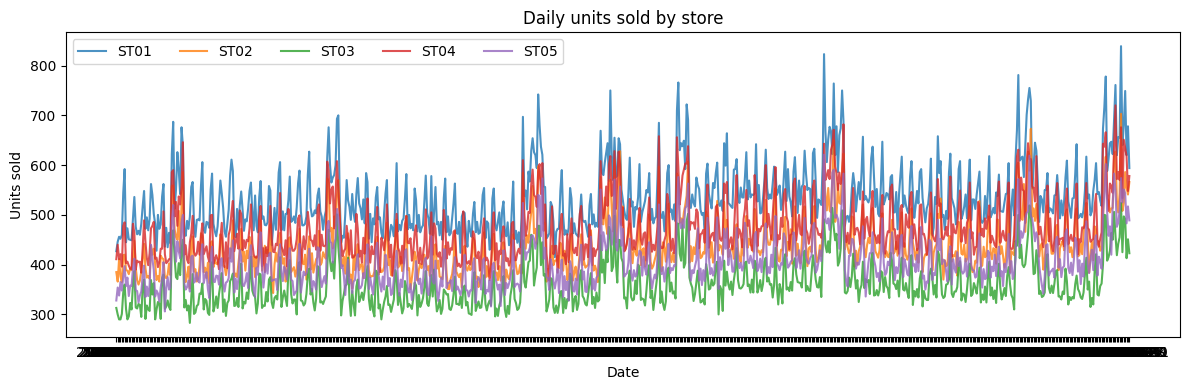

In [23]:
daily_store_summary = (
    data.groupby(["Date", "Store_ID"], as_index=False)
        .agg(Total_Units_Sold=("Units_Sold", "sum"),
             Active_Products=("Product_ID", "nunique"),
             Stockout_Rows=("Stockout_Flag", "sum"))
)

display(daily_store_summary.head())

plt.figure(figsize=(12, 4))
for store_id, group in daily_store_summary.groupby("Store_ID"):
    plt.plot(group["Date"], group["Total_Units_Sold"], label=store_id, alpha=0.8)
plt.title("Daily units sold by store")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend(ncol=5)
plt.tight_layout()
plt.show()

## 5. Build a few time-series features

These features describe what happened before the day being predicted:

- `Lag_1`: units sold yesterday
- `Lag_7`: units sold on the same weekday last week
- `Rolling_Mean_7`: average sales over the previous seven days
- `Rolling_Std_7`: how much sales varied over those previous seven days
- Calendar, promotion and price columns for extra context

Notice the `shift(1)` before the rolling calculation. Without it, today's sales would be included in today's input features. That would give the forecasting process information it would not actually have at prediction time (data leakage).


In [24]:
data = data.sort_values(["Store_ID", "Product_ID", "Date"]).copy()
group_cols = ["Store_ID", "Product_ID"]
grouped_sales = data.groupby(group_cols)["Units_Sold"]

data["Lag_1"] = grouped_sales.shift(1)
data["Lag_7"] = grouped_sales.shift(7)
data["Rolling_Mean_7"] = (
    data.groupby(group_cols)["Units_Sold"]
        .transform(lambda s: s.shift(1).rolling(7, min_periods=7).mean())
)
data["Rolling_Std_7"] = (
    data.groupby(group_cols)["Units_Sold"]
        .transform(lambda s: s.shift(1).rolling(7, min_periods=7).std())
)

feature_cols = [
    "Lag_1", "Lag_7", "Rolling_Mean_7", "Rolling_Std_7",
    "Day_Of_Week", "Month", "Is_Weekend", "Is_Holiday", "Promotion",
    "Selling_Price", "Inventory_Available"
]
display(data[["Date", "Store_ID", "Product_ID", "Units_Sold"] + feature_cols].head(12))

,Date,Store_ID,Product_ID,Units_Sold,Lag_1,Lag_7,Rolling_Mean_7,Rolling_Std_7,Day_Of_Week,Month,Is_Weekend,Is_Holiday,Promotion,Selling_Price,Inventory_Available
0,2024-01-01,ST01,P001,19,NaN,NaN,NaN,NaN,0,1,0,0,0,20.49,32
1,2024-01-02,ST01,P001,24,19.0,NaN,NaN,NaN,1,1,0,0,0,20.22,42
2,2024-01-03,ST01,P001,33,24.0,NaN,NaN,NaN,2,1,0,0,0,20.19,39
3,2024-01-04,ST01,P001,32,33.0,NaN,NaN,NaN,3,1,0,0,0,19.90,50
4,2024-01-05,ST01,P001,34,32.0,NaN,NaN,NaN,4,1,0,0,0,19.92,55
5,2024-01-06,ST01,P001,33,34.0,NaN,NaN,NaN,5,1,1,0,0,20.17,47
6,2024-01-07,ST01,P001,31,33.0,NaN,NaN,NaN,6,1,1,0,0,20.51,39
7,2024-01-08,ST01,P001,28,31.0,19.0,29.428571,5.682052,0,1,0,0,0,20.22,36
8,2024-01-09,ST01,P001,32,28.0,24.0,30.714286,3.545621,1,1,0,0,0,20.06,45
9,2024-01-10,ST01,P001,29,32.0,33.0,31.857143,1.951800,2,1,0,0,0,19.70,37


## 6. Start with two simple baselines

Before building a complicated model, it helps to check what simple rules can do.

1. **Naïve:** use the last value from the training period for every day in the forecast.
2. **Seasonal naïve (7-day):** repeat the most recent seven days. This is a simple way to carry forward a weekly pattern.

We compare predictions with actual sales using MAE, RMSE, WAPE and bias. Lower error values are generally better; bias tells us whether forecasts tend to be too high or too low. WAPE uses total absolute error divided by total actual sales, so days with tiny sales do not create huge percentage errors on their own.


In [25]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = predicted - actual
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    denominator = np.sum(np.abs(actual))
    wape = np.sum(np.abs(errors)) / denominator if denominator != 0 else np.nan
    bias = np.mean(errors)  # positive = over-forecast on average
    return {"MAE": mae, "RMSE": rmse, "WAPE": wape, "Bias": bias}


def naive_forecast(train_values, horizon):
    return np.repeat(float(train_values[-1]), horizon)


def seasonal_naive_forecast(train_values, horizon, season_length=7):
    if len(train_values) < season_length:
        raise ValueError("Not enough history for seasonal-naive forecast.")
    pattern = np.asarray(train_values[-season_length:], dtype=float)
    repeats = int(np.ceil(horizon / season_length))
    return np.tile(pattern, repeats)[:horizon]

## 7. Test the forecasts in date order

We should not randomly shuffle time-series rows. That could let the model use later dates to predict earlier ones, which would make the test unrealistically easy.

Instead, this notebook uses **rolling-origin backtesting**. For each fold, it trains using dates before a cutoff, predicts the next 28 days, then moves the cutoff forward and repeats. The training window grows over time. Both baselines are tested on the same dates so the comparison is fair.


In [26]:
HORIZON = 28
# Cutoffs leave at least one year of history and enough room for four test windows.
all_dates = pd.DatetimeIndex(sorted(data["Date"].unique()))
cutoff_positions = [365, 455, 545, 635]
cutoff_dates = [all_dates[p] for p in cutoff_positions if p + HORIZON <= len(all_dates)]

backtest_rows = []
for (store_id, product_id), series in data.groupby(group_cols):
    series = series.sort_values("Date")
    values = series["Units_Sold"].to_numpy(dtype=float)
    series_dates = pd.DatetimeIndex(series["Date"])

    for cutoff in cutoff_dates:
        train_mask = series_dates < cutoff
        test_mask = (series_dates >= cutoff) & (series_dates < cutoff + pd.Timedelta(days=HORIZON))
        train_values = values[train_mask]
        test_values = values[test_mask]

        if len(train_values) < 7 or len(test_values) != HORIZON:
            continue

        forecasts = {
            "Naive": naive_forecast(train_values, HORIZON),
            "Seasonal_Naive_7": seasonal_naive_forecast(train_values, HORIZON, 7)
        }

        for model_name, predictions in forecasts.items():
            metrics = calculate_metrics(test_values, predictions)
            backtest_rows.append({
                "Store_ID": store_id,
                "Product_ID": product_id,
                "Cutoff_Date": cutoff,
                "Model": model_name,
                **metrics
            })

backtest_results = pd.DataFrame(backtest_rows)
print("Backtest rows:", len(backtest_results))
display(backtest_results.head())

Backtest rows: 800


,Store_ID,Product_ID,Cutoff_Date,Model,MAE,RMSE,WAPE,Bias
0,ST01,P001,2024-12-31,Naive,6.642857,7.653197,0.208989,5.214286
1,ST01,P001,2024-12-31,Seasonal_Naive_7,8.571429,10.653638,0.269663,0.928571
2,ST01,P001,2025-03-31,Naive,6.678571,8.641676,0.139448,5.107143
3,ST01,P001,2025-03-31,Seasonal_Naive_7,7.535714,8.986100,0.157345,-6.607143
4,ST01,P001,2025-06-29,Naive,6.535714,7.844470,0.142412,0.107143


## 8. Compare the results

First compare the average metrics for the two baselines. Then look at product-level and store-level results. A single overall score can hide the fact that a forecast works well for some products but poorly for others.

Use the actual table values when describing the result; don't assume the seasonal baseline wins just because weekly patterns are present.


,MAE,RMSE,WAPE,Bias
Model,,,,
Seasonal_Naive_7,5.346964,6.719551,0.233576,0.395893
Naive,5.563036,6.665987,0.240501,0.661964


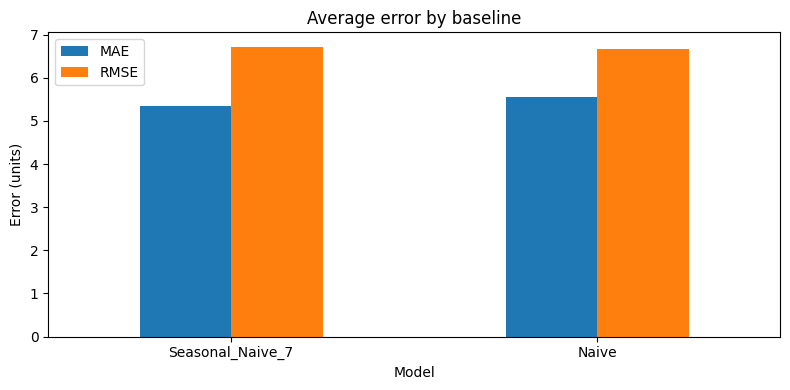

In [27]:
overall_results = (
    backtest_results.groupby("Model")[["MAE", "RMSE", "WAPE", "Bias"]]
        .mean()
        .sort_values("WAPE")
)
display(overall_results)

overall_results[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4), title="Average error by baseline")
plt.ylabel("Error (units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
product_results = (
    backtest_results.groupby(["Product_ID", "Model"], as_index=False)
        .agg(MAE=("MAE", "mean"), WAPE=("WAPE", "mean"))
        .merge(products[["Product_ID", "Product_Name", "Category"]], on="Product_ID", how="left")
)
display(product_results.sort_values(["Model", "WAPE"]).head(15))

store_results = (
    backtest_results.groupby(["Store_ID", "Model"], as_index=False)
        .agg(MAE=("MAE", "mean"), WAPE=("WAPE", "mean"))
        .merge(stores[["Store_ID", "City", "Store_Type"]], on="Store_ID", how="left")
)
display(store_results.sort_values(["Model", "WAPE"]))

,Product_ID,Model,MAE,WAPE,Product_Name,Category
10,P006,Naive,4.132143,0.204385,Cheese,Dairy
6,P004,Naive,5.167857,0.209780,Milk,Dairy
38,P020,Naive,4.010714,0.214131,Hand Wash,Personal Care
32,P017,Naive,3.873214,0.222074,Dish Soap,Household
16,P009,Naive,4.092857,0.222780,Rice 5kg,Staples
12,P007,Naive,5.260714,0.224667,Bread,Bakery
30,P016,Naive,4.255357,0.226097,Laundry Detergent,Household
4,P003,Naive,7.594643,0.228404,Cola,Beverages
2,P002,Naive,6.473214,0.228436,Orange Juice,Beverages
24,P013,Naive,6.453571,0.231329,Potato Chips,Snacks


,Store_ID,Model,MAE,WAPE,City,Store_Type
8,ST05,Naive,4.920089,0.236144,Lucknow,Suburban
4,ST03,Naive,4.470982,0.238665,Ghaziabad,Suburban
0,ST01,Naive,6.662500,0.239253,Delhi,Urban
6,ST04,Naive,6.018304,0.242006,Jaipur,Urban
2,ST02,Naive,5.743304,0.246436,Noida,Urban
1,ST01,Seasonal_Naive_7,6.218750,0.225395,Delhi,Urban
9,ST05,Seasonal_Naive_7,4.925446,0.233114,Lucknow,Suburban
5,ST03,Seasonal_Naive_7,4.342411,0.234125,Ghaziabad,Suburban
7,ST04,Seasonal_Naive_7,5.729911,0.234976,Jaipur,Urban
3,ST02,Seasonal_Naive_7,5.518304,0.240270,Noida,Urban


## 9. Does demand volatility matter?

Here, volatility is summarised using the coefficient of variation (standard deviation divided by mean sales) for each product-store series. The series are split into low, medium and high groups, then their forecast errors are compared.

This is a useful way to explore the data, not proof that volatility is the only reason a forecast misses. Promotions, stock limits and unusual events can matter too.


In [29]:
volatility = (
    data.groupby(group_cols)["Units_Sold"]
        .agg(Mean_Demand="mean", Std_Demand="std")
        .reset_index()
)
volatility["CV"] = volatility["Std_Demand"] / volatility["Mean_Demand"].replace(0, np.nan)
volatility["Volatility_Group"] = pd.qcut(
    volatility["CV"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

volatility_results = (
    backtest_results.merge(volatility[group_cols + ["CV", "Volatility_Group"]],
                           on=group_cols, how="left")
    .groupby(["Model", "Volatility_Group"], observed=False)
    .agg(MAE=("MAE", "mean"), RMSE=("RMSE", "mean"), WAPE=("WAPE", "mean"))
    .reset_index()
)
display(volatility_results)

,Model,Volatility_Group,MAE,RMSE,WAPE
0,Naive,Low,4.932359,5.901540,0.237845
1,Naive,Medium,4.908009,5.907235,0.239321
2,Naive,High,6.810924,8.144388,0.244224
3,Seasonal_Naive_7,Low,4.648268,5.845647,0.225098
4,Seasonal_Naive_7,Medium,4.889069,6.133329,0.238729
5,Seasonal_Naive_7,High,6.469538,8.136732,0.236804


## 10. Stockouts, promotions and uncertainty

### Stockouts

When inventory is limited, recorded sales can be lower than the number of customers who wanted the product. A model trained only on recorded sales may therefore underestimate demand. The stockout flag is a warning to interpret those observations carefully.

### Promotions

A promotion can temporarily increase sales. If the promotion is already planned and known, it can be included as a feature. If it is not known when the forecast is made, using it would give the model information it would not have in a real forecasting situation.

### Forecast interval

The example below adds historical error quantiles around a seasonal-naïve forecast. It gives a rough sense of uncertainty, but it is only an illustration: it is not a guarantee that 80% of future values will fall inside the band.


In [30]:
stockout_summary = (
    data.groupby(["Category"], as_index=False)
        .agg(Records=("Stockout_Flag", "size"),
             Stockout_Rate=("Stockout_Flag", "mean"),
             Mean_Units=("Units_Sold", "mean"))
        .sort_values("Stockout_Rate", ascending=False)
)
display(stockout_summary)

promo_summary = (
    data.groupby("Promotion")
        .agg(Mean_Units_Sold=("Units_Sold", "mean"),
             Median_Units_Sold=("Units_Sold", "median"),
             Observations=("Units_Sold", "size"))
)
display(promo_summary)

,Category,Records,Stockout_Rate,Mean_Units
3,Household,7310,0.019152,17.574829
6,Staples,14620,0.019083,19.119357
1,Beverages,10965,0.018787,29.743000
4,Personal Care,10965,0.018605,17.904332
0,Bakery,7310,0.018331,23.977565
2,Dairy,10965,0.018240,21.378659
5,Snacks,10965,0.018240,25.764888


,Mean_Units_Sold,Median_Units_Sold,Observations
Promotion,,,
0,21.403695,20.0,65443
1,28.984328,28.0,7657


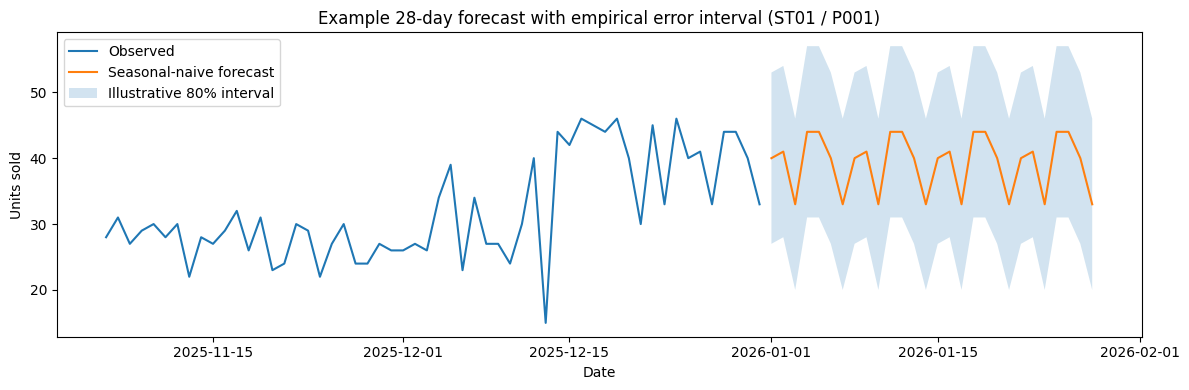

Historical seasonal-naive error quantiles: -13.0 13.0


In [32]:
data["Date"] = pd.to_datetime(data["Date"])

example_series = (
    data[(data["Store_ID"] == "ST01") & (data["Product_ID"] == "P001")]
    .sort_values("Date")
    .reset_index(drop=True)
)
y = example_series["Units_Sold"].to_numpy(dtype=float)

# Seasonal-naive residuals: each day vs same weekday one week earlier
seasonal_errors = y[7:] - y[:-7]
lower_error, upper_error = np.quantile(seasonal_errors, [0.10, 0.90])

last_week = y[-7:]
future_horizon = 28
point_forecast = np.tile(last_week, int(np.ceil(future_horizon / 7)))[:future_horizon]
lower = np.maximum(0, point_forecast + lower_error)
upper = np.maximum(lower, point_forecast + upper_error)

future_dates = pd.date_range(
    example_series["Date"].max() + pd.Timedelta(days=1),
    periods=future_horizon, freq="D",
)

plt.figure(figsize=(12, 4))
plt.plot(example_series["Date"].tail(56), y[-56:], label="Observed")
plt.plot(future_dates, point_forecast, label="Seasonal-naive forecast")
plt.fill_between(future_dates, lower, upper, alpha=0.2, label="Illustrative 80% interval")
plt.title("Example 28-day forecast with empirical error interval (ST01 / P001)")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()

print("Historical seasonal-naive error quantiles:", lower_error, upper_error)

## 11. Save the results

The tables are saved as CSV files in `outputs/`. This makes it easier to open the results separately or share them without having to rerun the notebook each time.


In [33]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

backtest_results.to_csv(OUTPUT_DIR / "backtest_results.csv", index=False)
overall_results.to_csv(OUTPUT_DIR / "overall_model_comparison.csv")
product_results.to_csv(OUTPUT_DIR / "product_error_analysis.csv", index=False)
store_results.to_csv(OUTPUT_DIR / "store_error_analysis.csv", index=False)
volatility_results.to_csv(OUTPUT_DIR / "volatility_error_analysis.csv", index=False)

print("Saved analysis outputs to:", OUTPUT_DIR.resolve())

Saved analysis outputs to: /content/outputs


## 12. What do the results tell us?

Use the outputs from the cells above to complete these points. It is better to write two or three accurate observations than to make broad claims that the numbers do not support.

- The baseline with the lower overall WAPE was: **[fill this in from the table]**.
- One product or store where errors stood out was: **[fill this in]**.
- The volatility comparison suggests: **[describe what you see; it may not show a clear pattern]**.
- One reason recorded sales might understate demand is: **[explain stockouts in your own words]**.

### Limitations to mention

- The dataset is simulated, so its patterns were designed for this exercise. Results should not be presented as evidence about a real retailer.
- We created lag and rolling features, but the two baselines do not use them. They are ready for a later machine-learning model comparison.
- The uncertainty band is a simple historical-error illustration, not a formally calibrated prediction interval.
- Stockouts mean observed sales can understate demand.

### Short reflection

After running the notebook, add a few sentences here in your own words:

1. Which part of the workflow made the most sense to you, and why?
2. What did you find out from comparing the two baselines?
3. If you had another day to improve the project, what would you try next?



## Quick explanation for the presentation

- **Row grain:** one product in one store on one date.
- **Lag:** a previous sales value used as a reference.
- **Rolling average:** a smoothed view of recent sales. We shift it so the current day is not included.
- **Baseline:** a simple forecast rule used as a point of comparison.
- **Backtesting:** repeat train-then-test checks in chronological order, as if we were moving through time.
- **MAE / RMSE:** average error size; RMSE penalises larger misses more.
- **WAPE:** total absolute error divided by total actual sales.
- **Bias:** positive means forecasts were higher than actual sales on average; negative means lower.

A good way to explain the project is to walk through the order: check the data, prepare past-only features, set a simple baseline, test it on future dates, and then inspect where the errors are larger.
